In [2]:
from degradation.model_degradation import DegradationNet, DegradationConfig, sample_show
import torch

test_sample_path = "/home/jeongyuseong/바탕화면/datasets/ImageNet/train/n01443537/n01443537_2.JPEG"
device = "cuda" if torch.cuda.is_available() else "cpu"

cfg = DegradationConfig(
    IMG_SIZE=224,
    EMBED_DIM=384,
    DEPTH=4,
)

model = DegradationNet(cfg)
model.eval().to(device)

/home/jeongyuseong/anaconda3/envs/pretext_task_gen/lib/python3.10/site-packages/torch/cuda/__init__.py:180: UserWarning: CUDA initialization: The NVIDIA driver on your system is too old (found version 12020). Please update your GPU driver by downloading and installing a new version from the URL: http://www.nvidia.com/Download/index.aspx Alternatively, go to: https://pytorch.org to install a PyTorch version that has been compiled with your version of the CUDA driver. (Triggered internally at /pytorch/c10/cuda/CUDAFunctions.cpp:119.)
  return torch._C._cuda_getDeviceCount() > 0


DegradationNet(
  (patch_embed): PatchEmbed(
    (proj): Conv2d(3, 384, kernel_size=(16, 16), stride=(16, 16))
  )
  (blocks): ModuleList(
    (0-3): 4 x HybridTransformerLayer(
      (norm1): LayerNorm((384,), eps=1e-05, elementwise_affine=True)
      (attn): MultiheadAttention(
        (out_proj): NonDynamicallyQuantizableLinear(in_features=384, out_features=384, bias=True)
      )
      (attn_proj_drop): Dropout(p=0.0, inplace=False)
      (norm2): LayerNorm((384,), eps=1e-05, elementwise_affine=True)
      (cnn_branch): TokenCNNBranch(
        (depthwise): Conv2d(384, 384, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=384)
        (pointwise): Conv2d(384, 384, kernel_size=(1, 1), stride=(1, 1))
        (act): GELU(approximate='none')
        (dropout): Dropout(p=0.0, inplace=False)
      )
      (norm3): LayerNorm((384,), eps=1e-05, elementwise_affine=True)
      (ffn): FeedForward(
        (fc1): Linear(in_features=384, out_features=1536, bias=True)
        (act): GELU

In [3]:
import numpy as np
from pathlib import Path
from PIL import Image
from typing import Tuple, Optional

def load_image_as_tensor(
    image_path: str,
    img_size: int = 224,
) -> Tuple[Image.Image, torch.Tensor]:
    """
    image_path -> PIL image, tensor [1,3,H,W]
    """
    path = Path(image_path)
    if not path.exists():
        raise FileNotFoundError(f"Image not found: {image_path}")

    img = Image.open(path).convert("RGB")
    img = img.resize((img_size, img_size))

    img_np = np.array(img).astype(np.float32) / 255.0  # [H,W,C]
    img_tensor = torch.from_numpy(img_np).permute(2, 0, 1).unsqueeze(0)  # [1,C,H,W]

    return img, img_tensor

In [4]:
pil_img, x = load_image_as_tensor(
    image_path=test_sample_path,
    img_size=224,
)
x = x.to(device)

with torch.no_grad():
    y, delta = model(x, return_delta=True)

In [5]:
print(x.shape)
print(delta.shape)
print(y.shape)

torch.Size([1, 3, 224, 224])
torch.Size([1, 196, 768])
torch.Size([1, 3, 224, 224])


In [6]:
from auto_encoder.model_auto_encoder import MaskedAutoencoderViT

/home/jeongyuseong/anaconda3/envs/pretext_task_gen/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [7]:
import sys
import os
import requests

import torch
import numpy as np

import matplotlib.pyplot as plt
from PIL import Image

from auto_encoder.model_auto_encoder import MaskedAutoencoderViT, MAEConfig, build_mae


cfg = MAEConfig(
    EMBED_DIM=768,
    DEPTH=12,
    NUM_HEADS=12,
)

model_ae = build_mae(cfg)


In [8]:
x.shape
x

tensor([[[[0.1216, 0.1137, 0.1098,  ..., 0.4745, 0.5490, 0.5961],
          [0.1255, 0.1176, 0.1098,  ..., 0.4980, 0.5451, 0.6000],
          [0.1255, 0.1176, 0.1098,  ..., 0.5059, 0.5490, 0.5843],
          ...,
          [0.3059, 0.3294, 0.3176,  ..., 0.4118, 0.4314, 0.4275],
          [0.3176, 0.3412, 0.3373,  ..., 0.4275, 0.4392, 0.4275],
          [0.3216, 0.3412, 0.3451,  ..., 0.4431, 0.4471, 0.4275]],

         [[0.1490, 0.1412, 0.1373,  ..., 0.4824, 0.5569, 0.6039],
          [0.1529, 0.1451, 0.1373,  ..., 0.5020, 0.5529, 0.6078],
          [0.1529, 0.1451, 0.1373,  ..., 0.5137, 0.5569, 0.5922],
          ...,
          [0.3176, 0.3412, 0.3294,  ..., 0.4196, 0.4353, 0.4314],
          [0.3294, 0.3529, 0.3490,  ..., 0.4275, 0.4392, 0.4275],
          [0.3333, 0.3529, 0.3569,  ..., 0.4471, 0.4471, 0.4275]],

         [[0.0784, 0.0745, 0.0745,  ..., 0.3843, 0.4627, 0.5098],
          [0.0824, 0.0784, 0.0745,  ..., 0.4078, 0.4588, 0.5137],
          [0.0824, 0.0784, 0.0745,  ..., 0

In [9]:
loss, pred, mask = model_ae(y, mask_ratio=0.0)

In [10]:
mask

tensor([[1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
         1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
         1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
         1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
         1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
         1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
         1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
         1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
         1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
         1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
         1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.]])

In [ ]:
print(x.shape)      # 원본 이미지의 텐서 변환결과
print(y.shape)      # degradationNet의 결과
print(loss.shape)   # auto_encoder 결과 loss
print(pred.shape)   # auto_encoder (mae 아키텍쳐)를 통환 이미지 복원결과
print(mask.shape)   # 마스크 결과 (근데 우린다 마스크해서 이제 의미없음. 전부다 1텐서임)
loss

torch.Size([1, 3, 224, 224])
torch.Size([1, 3, 224, 224])
torch.Size([])
torch.Size([1, 196, 768])
torch.Size([1, 196])


tensor(0.9440, grad_fn=<DivBackward0>)

In [12]:
latent, _, _ =  model_ae.forward_encoder(y, mask_ratio=0.0)
z = latent.mean(dim=1)

In [15]:
z.shape

torch.Size([1, 768])

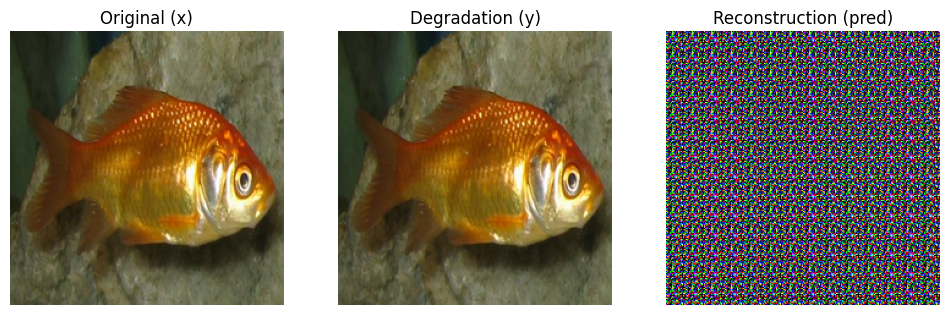

In [13]:
import matplotlib.pyplot as plt

# pred → 이미지 복원
img_recon = model_ae.unpatchify(pred)  # [1,3,224,224]

# tensor → numpy
def to_img(x):
    x = x.detach().cpu().squeeze(0)       # [3,H,W]
    x = x.permute(1, 2, 0).numpy()        # [H,W,3]
    x = np.clip(x, 0, 1)
    return x

x_img = to_img(x)
y_img = to_img(y)
recon_img = to_img(img_recon)

# 시각화


plt.figure(figsize=(12,4))

plt.subplot(1,3,1)
plt.title("Original (x)")
plt.imshow(x_img)
plt.axis("off")

plt.subplot(1,3,2)
plt.title("Degradation (y)")
plt.imshow(y_img)
plt.axis("off")

plt.subplot(1,3,3)
plt.title("Reconstruction (pred)")
plt.imshow(recon_img)
plt.axis("off")

plt.show()